# **Setup**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

np.set_printoptions(precision=4, suppress=True)

X_xor = np.array([
    [0., 0.],
    [0., 1.],
    [1., 0.],
    [1., 1.]
])

y_xor = np.array([0, 1, 1, 0])

print("XOR inputs shape:", X_xor.shape)
print("XOR labels:", y_xor)

XOR inputs shape: (4, 2)
XOR labels: [0 1 1 0]


# **Part A — Build the pieces**
## **TASK 01 — The four activations**

In [2]:
def relu(x):
    return np.maximum(0, x)

def sigmoid(x):
    return 1 / (1 + np.exp(-np.clip(x, -500, 500)))

def tanh(x):
    return np.tanh(x)

def softmax(x):
    x = np.asarray(x, dtype=float)

    # 1-D input 
    if x.ndim == 1:
        exp_x = np.exp(x - np.max(x))
        return exp_x / np.sum(exp_x)

    # 2-D input: calculate separately for each row
    exp_x = np.exp(x - np.max(x, axis=1, keepdims=True))
    return exp_x / np.sum(exp_x, axis=1, keepdims=True)

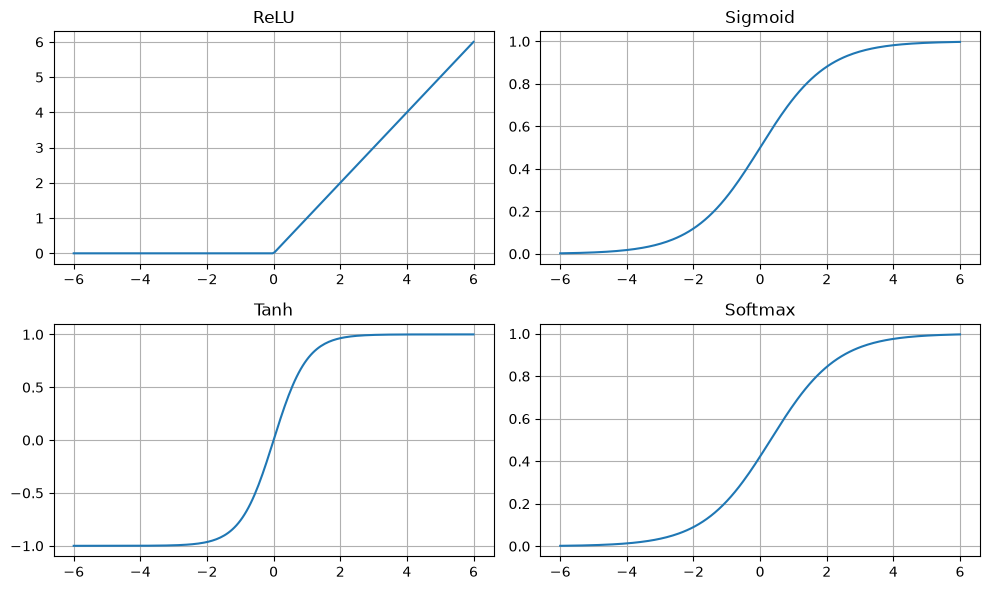

In [3]:
# Plot and Test 
x = np.linspace(-6, 6, 200)

fig, ax = plt.subplots(2, 2, figsize=(10, 6))

ax[0, 0].plot(x, relu(x))
ax[0, 0].set_title("ReLU")
ax[0, 0].grid()

ax[0, 1].plot(x, sigmoid(x))
ax[0, 1].set_title("Sigmoid")
ax[0, 1].grid()

ax[1, 0].plot(x, tanh(x))
ax[1, 0].set_title("Tanh")
ax[1, 0].grid()

scores = np.column_stack([x, np.zeros_like(x), -np.ones_like(x)])

ax[1, 1].plot(x, softmax(scores)[:, 0])
ax[1, 1].set_title("Softmax")
ax[1, 1].grid()

plt.tight_layout()
plt.show()

In [4]:
test = np.array([[-2., 0., 2.], [1., 3., -1.]])

print("Sigmoid between 0 and 1:", np.all((sigmoid(test) >= 0) & (sigmoid(test) <= 1)))
print("Tanh between -1 and 1:", np.all((tanh(test) >= -1) & (tanh(test) <= 1)))
print("ReLU Never negative:", np.all(relu(test) >= 0))

sm = softmax(test)

print("\nSoftmax Output:")
print(sm)
print("Each row sums to 1:", np.allclose(sm.sum(axis=1), 1))
print("Tanh-Sigmoid relationship:", np.allclose(tanh(test), 2 * sigmoid(2 * test) - 1))

Sigmoid between 0 and 1: True
Tanh between -1 and 1: True
ReLU Never negative: True

Softmax Output:
[[0.0159 0.1173 0.8668]
 [0.1173 0.8668 0.0159]]
Each row sums to 1: True
Tanh-Sigmoid relationship: True


## **TASK 02 — Numerical stability**

In [5]:
def softmax_naive(x):
    exp_x = np.exp(x)
    return exp_x / np.sum(exp_x)

large = np.array([1000., 999., 998.])

print("Naive Softmax:", softmax_naive(large))
print("Stable softmax:", softmax(large))

Naive Softmax: [nan nan nan]
Stable softmax: [0.6652 0.2447 0.09  ]


In [6]:
# Cross-entropy loss
def cross_entropy(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    y_pred = np.clip(y_pred, 1e-7, 1 - 1e-7)

    loss = -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))

    return loss

print(f"Clipped loss: {cross_entropy(np.array([1.]), np.array([0.])):.4f}")

Clipped loss: 16.1181


* Subtracting the maximum value in Softmax leaves the probabilities unchanged, because the common factor in the numerator and the denominator cancels out.

## **TASK 03 — A general forward pass**

In [7]:
def forward(X, params):
    a = X

    for i, (W, b) in enumerate(params):
        a = a @ W + b

        if i < len(params) - 1:
            a = relu(a)
        else:
            a = sigmoid(a)

    return a

In [8]:
# Automatically weights and bias
def build_params(layer_sizes, seed=42):
    rng = np.random.default_rng(seed)
    params = []

    for i in range(len(layer_sizes) - 1):
        input_size = layer_sizes[i]
        output_size = layer_sizes[i + 1]

        W = rng.normal(0, 0.5, (input_size, output_size))
        b = np.zeros((1, output_size))

        params.append((W, b))

    return params

In [9]:
# Three architecture layers
for sizes in [[2, 1], [2, 8, 1], [2, 8, 8, 8, 8, 1]]:
    params = build_params(sizes)
    output = forward(X_xor, params)

    print("\nArchitecture:", sizes)
    print("Output shape:", output.shape)


Architecture: [2, 1]
Output shape: (4, 1)

Architecture: [2, 8, 1]
Output shape: (4, 1)

Architecture: [2, 8, 8, 8, 8, 1]
Output shape: (4, 1)


In [10]:
# Count the parameters
params = build_params([2, 8, 8, 1])

total_parameters = sum(W.size + b.size for W, b in params)

print("Total Parameters:", total_parameters)

Total Parameters: 105


# **Part B — Prove the things you were told**
## **TASK 04 — Depth without activation is not depth**

In [11]:
# Build a network of 4 layers with no activation function anywhere.
def linear_forward(X, params, relu_layer=None):
    a = X

    for i, (W, b) in enumerate(params):
        a = a @ W + b

        if relu_layer == i:
            a = relu(a)

    return a


def collapse_params(params):
    W_final, b_final = params[0]

    W_final = W_final.copy()
    b_final = b_final.copy()

    for W, b in params[1:]:
        b_final = b_final @ W + b
        W_final = W_final @ W

    return W_final, b_final

In [12]:
# test the 4 and 10 layers
rng = np.random.default_rng(42)
X_random = rng.normal(size=(100, 3))

def make_linear_network(depth, seed):
    rng = np.random.default_rng(seed)
    sizes = [3] + [4] * (depth - 1) + [2]
    params = []

    for a, b in zip(sizes[:-1], sizes[1:]):
        W = rng.normal(0, 0.2, (a, b))
        bias = rng.normal(0, 0.2, (1, b))
        params.append((W, bias))

    return params

for depth in [4, 10]:
    params = make_linear_network(depth, 100 + depth)
    original = linear_forward(X_random, params)

    W, b = collapse_params(params)
    collapsed = X_random @ W + b
    difference = np.max(np.abs(original - collapsed))
    print(depth, "layers disagreement:", difference)

4 layers disagreement: 7.632783294297951e-17
10 layers disagreement: 2.7755575615628914e-17


In [13]:
# ReLU in One Layer
params = make_linear_network(4, 104)
original = linear_forward(X_random, params, relu_layer=1)

W, b = collapse_params(params)
collapsed = X_random @ W + b

difference = np.max(np.abs(original - collapsed))

print("Disagreement with one ReLU:", difference.round(4))

Disagreement with one ReLU: 0.1515


* Without activation, multiple linear layers can be combined into a single linear layer. Adding a ReLU generally means the output is no longer equivalent to a single linear transformation. Minor numerical discrepancies may arise due to floating-point rounding.

## **TASK 05 — The XOR ceiling**

In [14]:
def random_predict(X, sizes, seed, use_relu):
    rng = np.random.default_rng(seed)
    params = []

    for a, b in zip(sizes[:-1], sizes[1:]):
        W = rng.normal(0, 1, (a, b))
        bias = rng.normal(0, 1, (1, b))
        params.append((W, bias))

    output = X.copy()

    for i, (W, bias) in enumerate(params):
        output = output @ W + bias

        if i < len(params) - 1:
            if use_relu:
                output = relu(output)
        else:
            output = sigmoid(output)

    return (output.ravel() >= 0.5).astype(int)

In [15]:
def accuracy(prediction):
    return np.mean(prediction == y_xor)

attempts = 5000
depths = [1, 2, 5, 10]

for depth in depths:
    if depths == 1:
        sizes = [2, 1]
    else:
        sizes = [2] + [4] * (depth - 1) + [1]

    best_linear = 0
    best_relu = 0
    first_success = None

    for attempt in range(attempts):
        seed = 100000 + depth * 10000 + attempt

        p1 = random_predict(X_xor, sizes, seed, False)
        best_linear = max(best_linear, accuracy(p1))

        p2 = random_predict(X_xor, sizes, seed, True)
        acc = accuracy(p2)

        best_relu = max(best_relu, acc)

        if acc == 1.0 and first_success is None:
            first_success = attempt + 1

        print(
            "Depth:", depth,
            "| Linear Best:", best_linear,
            "| ReLU Best:", best_relu,
            "| First ReLU Success:", first_success
        )

Depth: 1 | Linear Best: 0.5 | ReLU Best: 0.5 | First ReLU Success: None
Depth: 1 | Linear Best: 0.5 | ReLU Best: 0.5 | First ReLU Success: None
Depth: 1 | Linear Best: 0.75 | ReLU Best: 0.75 | First ReLU Success: None
Depth: 1 | Linear Best: 0.75 | ReLU Best: 0.75 | First ReLU Success: None
Depth: 1 | Linear Best: 0.75 | ReLU Best: 0.75 | First ReLU Success: None
Depth: 1 | Linear Best: 0.75 | ReLU Best: 0.75 | First ReLU Success: None
Depth: 1 | Linear Best: 0.75 | ReLU Best: 0.75 | First ReLU Success: None
Depth: 1 | Linear Best: 0.75 | ReLU Best: 0.75 | First ReLU Success: None
Depth: 1 | Linear Best: 0.75 | ReLU Best: 0.75 | First ReLU Success: None
Depth: 1 | Linear Best: 0.75 | ReLU Best: 0.75 | First ReLU Success: None
Depth: 1 | Linear Best: 0.75 | ReLU Best: 0.75 | First ReLU Success: None
Depth: 1 | Linear Best: 0.75 | ReLU Best: 0.75 | First ReLU Success: None
Depth: 1 | Linear Best: 0.75 | ReLU Best: 0.75 | First ReLU Success: None
Depth: 1 | Linear Best: 0.75 | ReLU Best: 

## **TASK 06 — Solve XOR by hand, your own way**

In [16]:
W1 = np.array([
    [1., -1.],
    [-1., 1.]
])

b1 = np.array([[0., 0.]])

W2 = np.array([
    [20.], [20.]
])

b2 = np.array([[-10.]])

hidden = relu(X_xor @ W1 + b1)

output = sigmoid(hidden @ W2 + b2).ravel()
prediction = (output >= 0.5).astype(int)

print("Hidden Activations:")
print(hidden)

print("\nProbabilities:", output)
print("Predictions:", prediction)
print("Actual:", y_xor)
print("Accuracy:", np.mean(prediction == y_xor))
print("Cross-Entropy:", cross_entropy(y_xor, output))

Hidden Activations:
[[0. 0.]
 [0. 1.]
 [1. 0.]
 [0. 0.]]

Probabilities: [0. 1. 1. 0.]
Predictions: [0 1 1 0]
Actual: [0 1 1 0]
Accuracy: 1.0
Cross-Entropy: 4.539889921682063e-05


* **Single hidden neuron:** In a standard architecture, it is not possible to perfectly separate the XOR classes using a single ReLU hidden neuron and a sigmoid output. The threshold-based decision of a single ReLU unit effectively creates a straight-line boundary (or a half-space), which cannot separate the alternating corners of the XOR pattern.


In [17]:
# Solve xor with tanh activation
W1_tanh = np.array([
    [10., 10.],
    [10., 10.]
])

b1_tanh = np.array([[-5., -15.]])

W2_tanh = np.array([
    [10.], [-10.]
])

b2_tanh = np.array([[-10.]])

hidden_tanh = tanh(X_xor @ W1_tanh + b1_tanh)
output_tanh = sigmoid(hidden_tanh @ W2_tanh + b2_tanh).ravel()

prediction_tanh = (output_tanh >= 0.5).astype(int)

print("Tanh hidden Activations:")
print(hidden_tanh)

print("\nTanh Probabilities:", output_tanh)
print("Tanh Accuracy:", np.mean(prediction_tanh == y_xor))

Tanh hidden Activations:
[[-0.9999 -1.    ]
 [ 0.9999 -0.9999]
 [ 0.9999 -0.9999]
 [ 1.      0.9999]]

Tanh Probabilities: [0. 1. 1. 0.]
Tanh Accuracy: 1.0


In [18]:
# reverse weights and biases
W2_xnor = -W2
b2_xnor = -b2

output_xnor = sigmoid(hidden @ W2_xnor + b2_xnor).ravel()
prediction_xnor = (output_xnor >= 0.5).astype(int)

print("XNOR predictions:", prediction_xnor)
print("XNOR Actual:", 1 - y_xor)
print("Accuracy:", np.mean(prediction_xnor == (1 - y_xor)))

XNOR predictions: [1 0 0 1]
XNOR Actual: [1 0 0 1]
Accuracy: 1.0


# **Part C — Loss functions**
## **TASK 07 — MSE against cross-entropy**

In [20]:
def mse_loss(y_true, y_pred):
    return np.mean((np.asarray(y_true) - np.asarray(y_pred)) ** 2)

def ce_loss(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.clip(np.asarray(y_pred, dtype=float), 1e-7, 1 - 1e-7)

    return -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))

In [24]:
probabilities = [0.999, 0.99, 0.9, 0.75, 0.5, 0.25, 0.1, 0.01, 0.001]

print("Probability | MSE | Cross-Entropy")

for p in probabilities:
    mse = mse_loss([1], p)
    ce = ce_loss([1], p)

    print(f"{p:.3f} | {mse:.6f} | {ce:.6f}")

Probability | MSE | Cross-Entropy
0.999 | 0.000001 | 0.001001
0.990 | 0.000100 | 0.010050
0.900 | 0.010000 | 0.105361
0.750 | 0.062500 | 0.287682
0.500 | 0.250000 | 0.693147
0.250 | 0.562500 | 1.386294
0.100 | 0.810000 | 2.302585
0.010 | 0.980100 | 4.605170
0.001 | 0.998001 | 6.907755


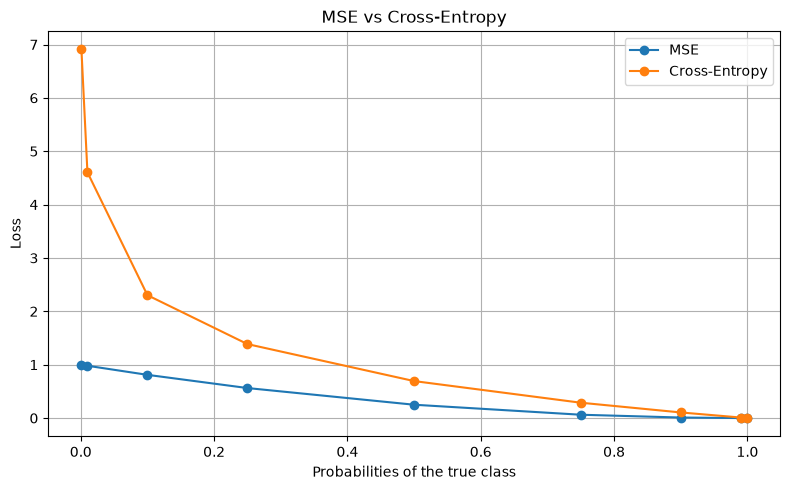

In [25]:
# Plot the graph
fig, ax = plt.subplots(figsize=(8, 5))

mse_values = [mse_loss([1], [p]) for p in probabilities]
ce_values = [ce_loss([1], [p]) for p in probabilities]

ax.plot(probabilities, mse_values, marker="o", label="MSE")
ax.plot(probabilities, ce_values, marker="o", label="Cross-Entropy")

ax.set_title("MSE vs Cross-Entropy")
ax.set_xlabel("Probabilities of the true class")
ax.set_ylabel("Loss")
ax.legend()
ax.grid()

plt.tight_layout()
plt.show()

In [26]:
# hand-built XOR
random_params = build_params([2, 4, 1], seed=46)
random_predictions = forward(X_xor, random_params).ravel()

half_prediction = np.full(4, 0.5)

model = {
    "Hand-build XOR": output,
    "Random network": random_predictions,
    "Always 0.5": half_prediction
}


for name, pred in model.items():
    print(name)
    print("MSE:", mse_loss(y_xor, pred))
    print("Cross-Entropy:", ce_loss(y_xor, pred))
    print()

Hand-build XOR
MSE: 2.060966482721474e-09
Cross-Entropy: 4.539889921682063e-05

Random network
MSE: 0.24266258444525762
Cross-Entropy: 0.6784636867701916

Always 0.5
MSE: 0.25
Cross-Entropy: 0.6931471805599453



In [37]:
# Test on ten different seeds 
random_losses = []

for seed in range(10):
    params = build_params([2, 4, 1], seed=seed)
    pred = forward(X_xor, params).ravel()

    random_losses.append(ce_loss(y_xor, pred))


print("Losses:", random_losses)
print("Minimum:", round(min(random_losses), 4))
print("Maximum:", round(max(random_losses), 4))
print("Spread:", round((max(random_losses) - min(random_losses)), 4))

Losses: [np.float64(0.7086749173140303), np.float64(0.685726466254087), np.float64(0.7100641924587716), np.float64(0.711523281250771), np.float64(0.6971137743552178), np.float64(0.6876965956484333), np.float64(0.6991896446067044), np.float64(0.6887266173652359), np.float64(0.6937358728851358), np.float64(0.7423214111844406)]
Minimum: 0.6857
Maximum: 0.7423
Spread: 0.0566


In [38]:
print("Calculated:", ce_loss(y_xor, half_prediction))
print("Expected:", np.log(2))

Calculated: 0.6931471805599453
Expected: 0.6931471805599453


* In binary classification, cross-entropy penalizes confident, incorrect predictions very heavily. For binary labels and probabilities, the maximum value of MSE is 1, whereas cross-entropy has no finite upper limit.

# **Part D — Universal approximation**
## **TASK 08 — Build a curve out of hinges**

In [39]:
def target_function(x):
    return np.sin(2 * x) + 0.3 * x


X_train = np.linspace(-3, 3, 300).reshape(-1, 1)
y_train = target_function(X_train.ravel())

widths = [2, 5, 20, 100, 500]
results = {}

for width in widths:
    rng = np.random.default_rng(8000 + width)

    W = rng.normal(0, 1, (1, width))
    b = rng.uniform(-3, 3, (1, width))

    hidden = relu(X_train @ W + b)

    # add the bias column
    design = np.column_stack([np.ones(len(X_train)), hidden])

    # Solve the output weights
    output_weights, _, _, _ = np.linalg.lstsq(design, y_train, rcond=None)

    prediction = design @ output_weights
    mse = np.mean((y_train - prediction) ** 2)

    results[width] = [W, b, output_weights]

    print("Width:", width, "| Training MSE", mse )

Width: 2 | Training MSE 0.4828865603799984
Width: 5 | Training MSE 0.25997059299636466
Width: 20 | Training MSE 0.0414767713360869
Width: 100 | Training MSE 0.0006448283010013524
Width: 500 | Training MSE 7.614296684809771e-07


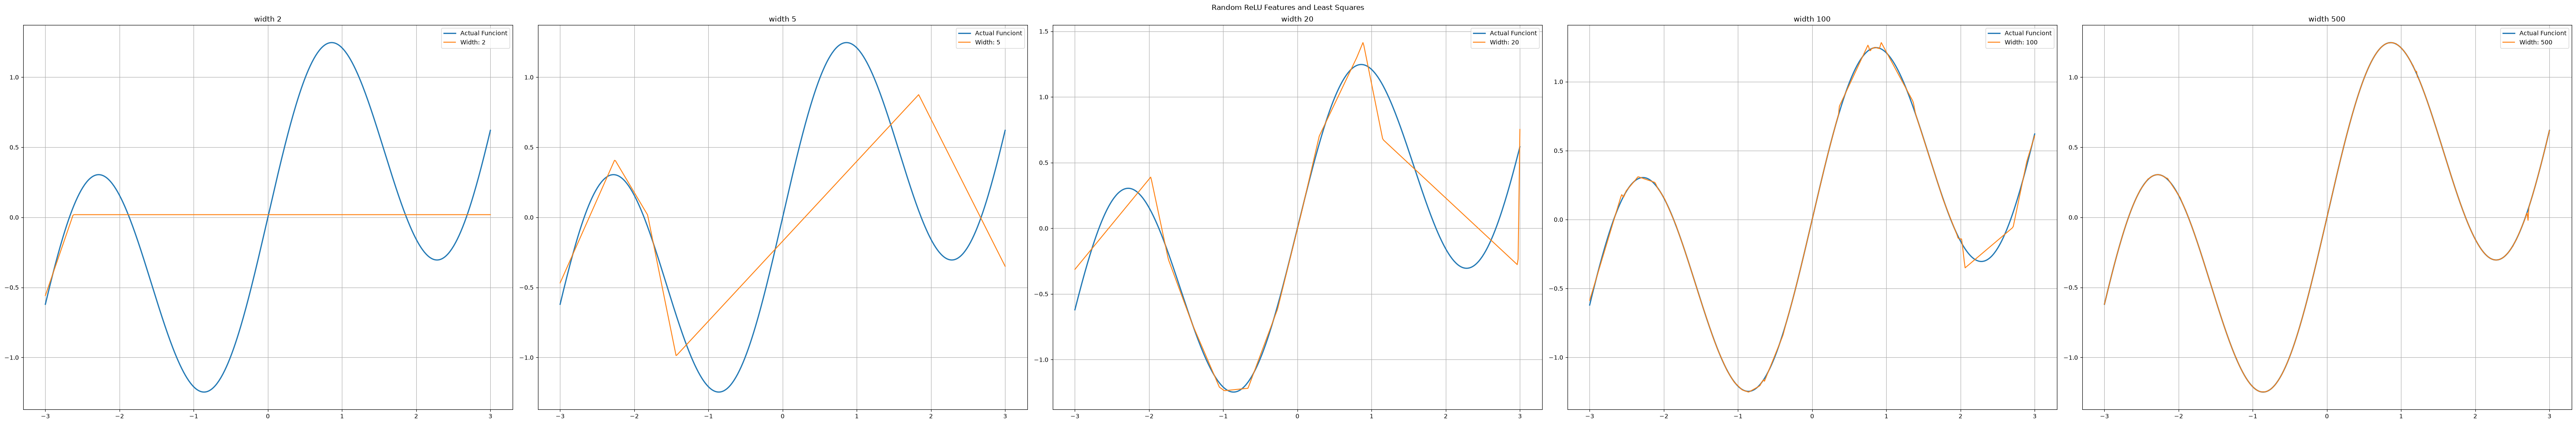

In [49]:
# plot the all five fits
x_plot = np.linspace(-3, 3, 500).reshape(-1, 1)
y_plot = target_function(x_plot.ravel())

fig, ax = plt.subplots(1, len(widths), figsize=(12 * len(widths), 10))

if len(widths) == 1:
    axes = [axes]


for ax, width in zip(ax, widths):
    W, b, output_weights = results[width]

    hidden = relu(x_plot @ W + b)

    design = np.column_stack([np.ones(len(x_plot)), hidden])

    prediction = design @ output_weights

    ax.plot(x_plot.ravel(), y_plot, label="Actual Funciont", lw=2)
    ax.plot(x_plot.ravel(), prediction, label=f"Width: {width}")

    ax.set_title(f"width {width}")
    ax.legend()
    ax.grid()

fig.suptitle("Random ReLU Features and Least Squares")
plt.tight_layout()
plt.show()

In [53]:
# Test on new data
rng = np.random.default_rng(2026)

x_new = rng.uniform(-3, 3, 200).reshape(-1, 1)
y_new = target_function(x_new.ravel())

W, b, output_weights = results[500]

hidden_new = relu(x_new @ W + b)

design_new = np.column_stack([np.ones(len(x_new)), hidden_new])
prediction_new = design_new @ output_weights

new_mse = np.mean((y_new - prediction_new) ** 2)

print("Width 500 -- new data MSE:", new_mse)

Width 500 -- new data MSE: 4.582658674020755e-06


In [56]:
x_out = np.linspace(4, 6, 200).reshape(-1, 1)
y_out = target_function(x_out.ravel())

hidden_out = relu(x_out @ W + b)

design_out = np.column_stack([np.ones(len(x_out)), hidden_out])

prediction_out = design_out @ output_weights

outside_mse = np.mean((y_out - prediction_out) ** 2)

print("Outside range MSE:", outside_mse.round(4))

Outside range MSE: 135.775


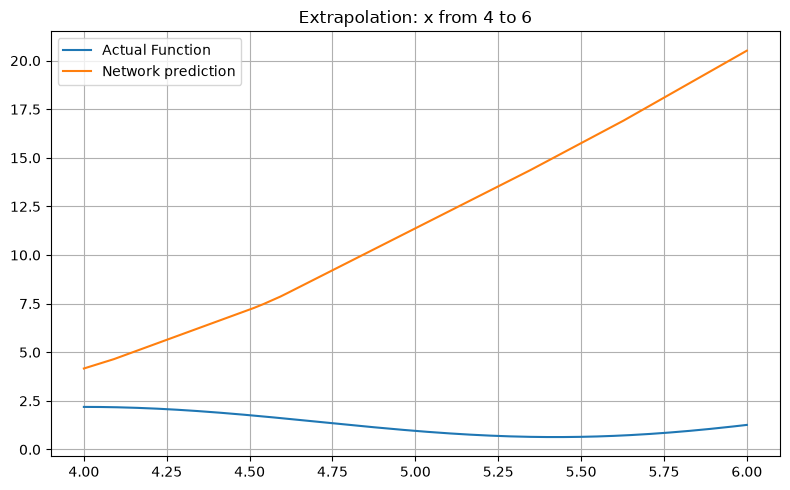

In [57]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(x_out.ravel(), y_out, label="Actual Function")
ax.plot(x_out.ravel(), prediction_out, label="Network prediction")

ax.set_title("Extrapolation: x from 4 to 6")
ax.legend()
ax.grid()

plt.tight_layout()
plt.show()

* Performing well within the training range does not imply that the network will also be accurate outside of that range. The universal approximation theorem concerns approximation over a bounded range; it does not guarantee accurate extrapolation for every possible input.

# **Part E — Push further**

In [58]:
# Dead ReLU
X_dead = np.array([[-2.], [-1.], [0.], [1.], [2.]])
W_dead = np.array([[-1.]])
b_dead = np.array([[-10.]])

z = X_dead @ W_dead + b_dead
activation = relu(z)

print("Pre-Activation:")
print(z)

print("\nReLU output:")
print(activation)

print("\nAll outputs Zero:", np.all(activation == 0))

Pre-Activation:
[[ -8.]
 [ -9.]
 [-10.]
 [-11.]
 [-12.]]

ReLU output:
[[0.]
 [0.]
 [0.]
 [0.]
 [0.]]

All outputs Zero: True


* ReLU produces a zero output for negative inputs. In gradient-based training, the derivative on the negative side is zero; consequently, the neuron receives no gradient for updates and may remain "dead."

In [59]:
# Multiply the inputs by 100 and divide by 100.
params = build_params([2, 8, 8, 1], seed=46)

X = np.array([[-0.2, -0.4], [0.8, 0.3], [-0.5, 0.7]])

def check_activation_sizes(X, params):
    a = X.copy()

    print("Input maximum:", np.max(np.abs(a)))

    for i, (W, b) in enumerate(params):
        a = a @ W + b

        if i < len(params) - 1:
            a = relu(a)
        else:
            a = sigmoid(a)

        print("Layer", i + 1, "Maximum Activation:", np.max(np.abs(a)))


print("INPUT SCALE = 1")
check_activation_sizes(X, params)

print("\nINPUT SCALE = 100")
check_activation_sizes(X * 100, params)

print("\nINPUT SCALE = 0.01")
check_activation_sizes(X * 0.01, params)

INPUT SCALE = 1
Input maximum: 0.8
Layer 1 Maximum Activation: 0.7133574545250012
Layer 2 Maximum Activation: 0.7400750211967025
Layer 3 Maximum Activation: 0.6050149584485973

INPUT SCALE = 100
Input maximum: 80.0
Layer 1 Maximum Activation: 71.33574545250012
Layer 2 Maximum Activation: 74.00750211967025
Layer 3 Maximum Activation: 1.0

INPUT SCALE = 0.01
Input maximum: 0.008
Layer 1 Maximum Activation: 0.007133574545250012
Layer 2 Maximum Activation: 0.007400750211967026
Layer 3 Maximum Activation: 0.5010660116041514


* Changing the input scale can alter the magnitude of layer activations. Large activations may push the sigmoid function toward saturation, while very small activations can result in extremely small outputs in certain layers.

# **Final Report**

**1. What is neuron?**
* A neuron multiplies inputs by weights, adds a bias, and applies an activation function. Its output is passed to the next layer or used to make a final prediction.


**2. Linear layer collapse**
* Multiple linear layers can be combined into one equivalent linear layer by multiplying weights and combining biases. Adding a nonlinear activation such as ReLU generally prevents this collapse.


**3. XOR solution**
* My hidden neurons compute relu(x1 - x2) and relu(x2 - x1). At least one neuron activates when the inputs differ, allowing the network to represent XOR.


**4. Why Cross-Entropy?**
* Cross-entropy strongly penalizes confident incorrect predictions. MSE is bounded by 1 for binary labels and probabilities, whereas cross-entropy can grow without a finite upper limit.


**5. Universal approximation**
* The ReLU network can approximate a function over a bounded interval. A good fit on the training interval does not guarantee accurate predictions outside that interval.


**6. Open question**
* How can we choose useful hidden-layer weights efficiently for a complex target function instead of relying on random weights?